# Topic modeling of osiris courses

### imports

In [2]:
# !pip install top2vec
# !pip install top2vec[sentence_transformers]
# !pip install top2vec[sentence_encoders]

In [3]:
import numpy as np
import pandas as pd

from top2vec import Top2Vec
import re, string

### Load data

In [23]:
# data = pd.read_csv("BACKUP DATA/created_data/cleaned_data/osiris.csv")
data = pd.read_excel("BACKUP DATA/created_data/CORRECT_DATA/raw_data_inh_doel.xlsx")

print(list(data.columns))

['CURSUS', 'LANGE_NAAM_NL', 'DOCENT_ROL', 'LABEL', 'OSS_ADF_UTILITY.HTML_TO_TEXT(H.INHOUD)']


In [24]:

# Naam van de kolom met de tekst
tekst_kolom = "OSS_ADF_UTILITY.HTML_TO_TEXT(H.INHOUD)"

# Elke waarde uit LABEL wordt een aparte kolom
df_combined = (
    data.pivot(
        index=["CURSUS", "LANGE_NAAM_NL", "DOCENT_ROL"],
        columns="LABEL",
        values=tekst_kolom
    )
    .reset_index()
)

# Naam van de kolommen netjes maken
df_combined.columns.name = None


# data.head(8)

In [29]:
df_combined.dropna(subset=['DOEL', 'INHOUD'], how='all', inplace=True)
df_combined = df_combined[['CURSUS', 'LANGE_NAAM_NL', 'DOCENT_ROL', 'DOEL', 'INHOUD']]
# print(df_combined)
data = df_combined
data.head(10)

,CURSUS,LANGE_NAAM_NL,DOCENT_ROL,DOEL,INHOUD
4,ASB-GRIPSCRIP,Grip op je Scriptie,Baars / Brasjen / Breemen / Bruinsma / Buiks /...,Ervaar je problemen in je scriptievoortgang? M...,NaN
29,FTR-CC300,Persoonlijke en professionele ontwikkeling 3: ...,Linssen / Rietdijk /,Aan het eind van de cursus kun je:\n \n- je ei...,Deze cursus staat in het teken van de zoektoch...
30,FTR-EDU100,Onderwijs in filosofie en levensbeschouwing,Kuijlen /,Na afloop van de cursus kan je:\n \n \n- enkel...,"De tradities van filosofie, religie en levensb..."
35,FTR-FIB101,Geschiedenis van de antieke filosofie,Bakker /,Na afloop van de cursus:\n \n- ken je de globa...,In deze cursus maak je kennis met de belangrij...
36,FTR-FIB102,Geschiedenis van de middeleeuwse filosofie,Otto /,Na afloop van de cursus kun je:\n \n- de belan...,In deze cursus maak je kennis met de belangrij...
37,FTR-FIB103,Geschiedenis van de moderne filosofie,Riemersma /,Na afloop van de cursus kun je:\n \n \n- de be...,Deze cursus geeft je een overzicht van de gesc...
38,FTR-FIB104,Geschiedenis van de hedendaagse filosofie,Strien /,Na afloop van de cursus kun je:\n \n- de belan...,Tijdens deze cursus bestuderen we de twintigst...
39,FTR-FIB106,Logica,Thijs / Tiel /,Na afloop van de cursus:\n \n- kun je de begri...,Startend vanuit een aantal historische mijlpal...
40,FTR-FIB107,Taalfilosofie,Bary /,Na afloop van de cursus kun je:\n• de voor- en...,Deze cursus biedt een inleiding in de taalfilo...
41,FTR-FIB109,Metafysica,Heiden /,Na afloop van de cursus kun je:\n \n- de eleme...,De metafysica houdt zich als eerste filosofie ...


In [59]:
# merge text data
# text = data['combined']
# df["tekst"] = (
#     df["INHOUD"].fillna("") + " " +
#     df["DOEL"].fillna("")
# )
data['combined'] = data['DOEL'].astype(str).fillna("") + ' ' + data['INHOUD'].astype(str).fillna("")
data['combined'] = data['combined'].astype(str)
text = data['combined'].iloc[1]
data.head()
print(text)

Aan het eind van de cursus kun je:
 
- je eigen positie, visie, voorkeuren en drijfveren verwoorden binnen het eigen vakgebied, alsmede de eigen kwaliteiten en ambities, maar tevens aangeven in welke mate nog competenties zijn gewenst [persoonlijk-professioneel profiel];
 
- een wetenschappelijk verantwoorde bijdrage leveren door middel van een kritische analyse van een omstreden kwestie, alsmede door middel van een journalistiek product [filosofie, theologie, religiewetenschap voor een breder publiek];
 
- een project van beperkte omvang realiseren, waarin het gaat om een concreet vakwetenschappelijk onderzoek binnen een gekozen domein van de samenleving [vakwetenschappelijke toepassing binnen een professioneel veld]. Deze cursus staat in het teken van de zoektocht naar de eigen professionele houding en positie. In de eindfase van de bacheloropleiding is het alleszins gerechtvaardigd om die zoektocht aan te gaan. Tijdens je studie heb je al heel veel kennis opgedaan van de wijsgerige,

In [60]:
# print(text.iloc[1])
text = re.split(r'[,!?;\s]+', str(text))
# data.head(10)
print(text)

['Aan', 'het', 'eind', 'van', 'de', 'cursus', 'kun', 'je:', '-', 'je', 'eigen', 'positie', 'visie', 'voorkeuren', 'en', 'drijfveren', 'verwoorden', 'binnen', 'het', 'eigen', 'vakgebied', 'alsmede', 'de', 'eigen', 'kwaliteiten', 'en', 'ambities', 'maar', 'tevens', 'aangeven', 'in', 'welke', 'mate', 'nog', 'competenties', 'zijn', 'gewenst', '[persoonlijk-professioneel', 'profiel]', '-', 'een', 'wetenschappelijk', 'verantwoorde', 'bijdrage', 'leveren', 'door', 'middel', 'van', 'een', 'kritische', 'analyse', 'van', 'een', 'omstreden', 'kwestie', 'alsmede', 'door', 'middel', 'van', 'een', 'journalistiek', 'product', '[filosofie', 'theologie', 'religiewetenschap', 'voor', 'een', 'breder', 'publiek]', '-', 'een', 'project', 'van', 'beperkte', 'omvang', 'realiseren', 'waarin', 'het', 'gaat', 'om', 'een', 'concreet', 'vakwetenschappelijk', 'onderzoek', 'binnen', 'een', 'gekozen', 'domein', 'van', 'de', 'samenleving', '[vakwetenschappelijke', 'toepassing', 'binnen', 'een', 'professioneel', 'veld

In [64]:
# train model
model = Top2Vec(data.combined.values, embedding_model="universal-sentence-encoder-multilingual")

2026-09-14 12:43:49,514 - top2vec - INFO - Pre-processing documents for training
INFO:top2vec:Pre-processing documents for training
C:\Users\sue-e\anaconda3\envs\OvP\lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
2026-09-14 12:43:51,810 - top2vec - INFO - Downloading universal-sentence-encoder-multilingual model
INFO:top2vec:Downloading universal-sentence-encoder-multilingual model
2026-09-14 12:44:11,788 - top2vec - INFO - Creating joint document/word embedding
INFO:top2vec:Creating joint document/word embedding
2026-09-14 12:44:54,045 - top2vec - INFO - Creating lower dimension embedding of documents
INFO:top2vec:Creating lower dimension embedding of documents
2026-09-14 12:45:05,050 - top2vec - INFO - Finding dense areas of documents
INFO:top2vec:Finding dense areas of documents
C:\Users\sue-e\anaconda3\envs\OvP\lib\site-packages\sklearn\utils\deprecation.py:132: Fu

In [65]:
model.get_num_topics()

39

In [66]:
model.topic_words

array([['taalvaardigheid', 'linguistic', 'languages', ..., 'interaction',
        'interactions', 'communication'],
       ['jurisprudentie', 'rechtspraktijk', 'juridische', ...,
        'lecturer', 'internship', 'theoretische'],
       ['quantum', 'physics', 'chemistry', ..., 'elementen', 'studenten',
        'hoorcolleges'],
       ...,
       ['thesis', 'independent', 'independently', ..., 'onderwerpen',
        'without', 'complete'],
       ['thesis', 'literatuur', 'academic', ..., 'criteria', 'includes',
        'critical'],
       ['belastingrecht', 'fiscale', 'jurisprudentie', ..., 'lectures',
        'ethics', 'wetgeving']], dtype='<U15')

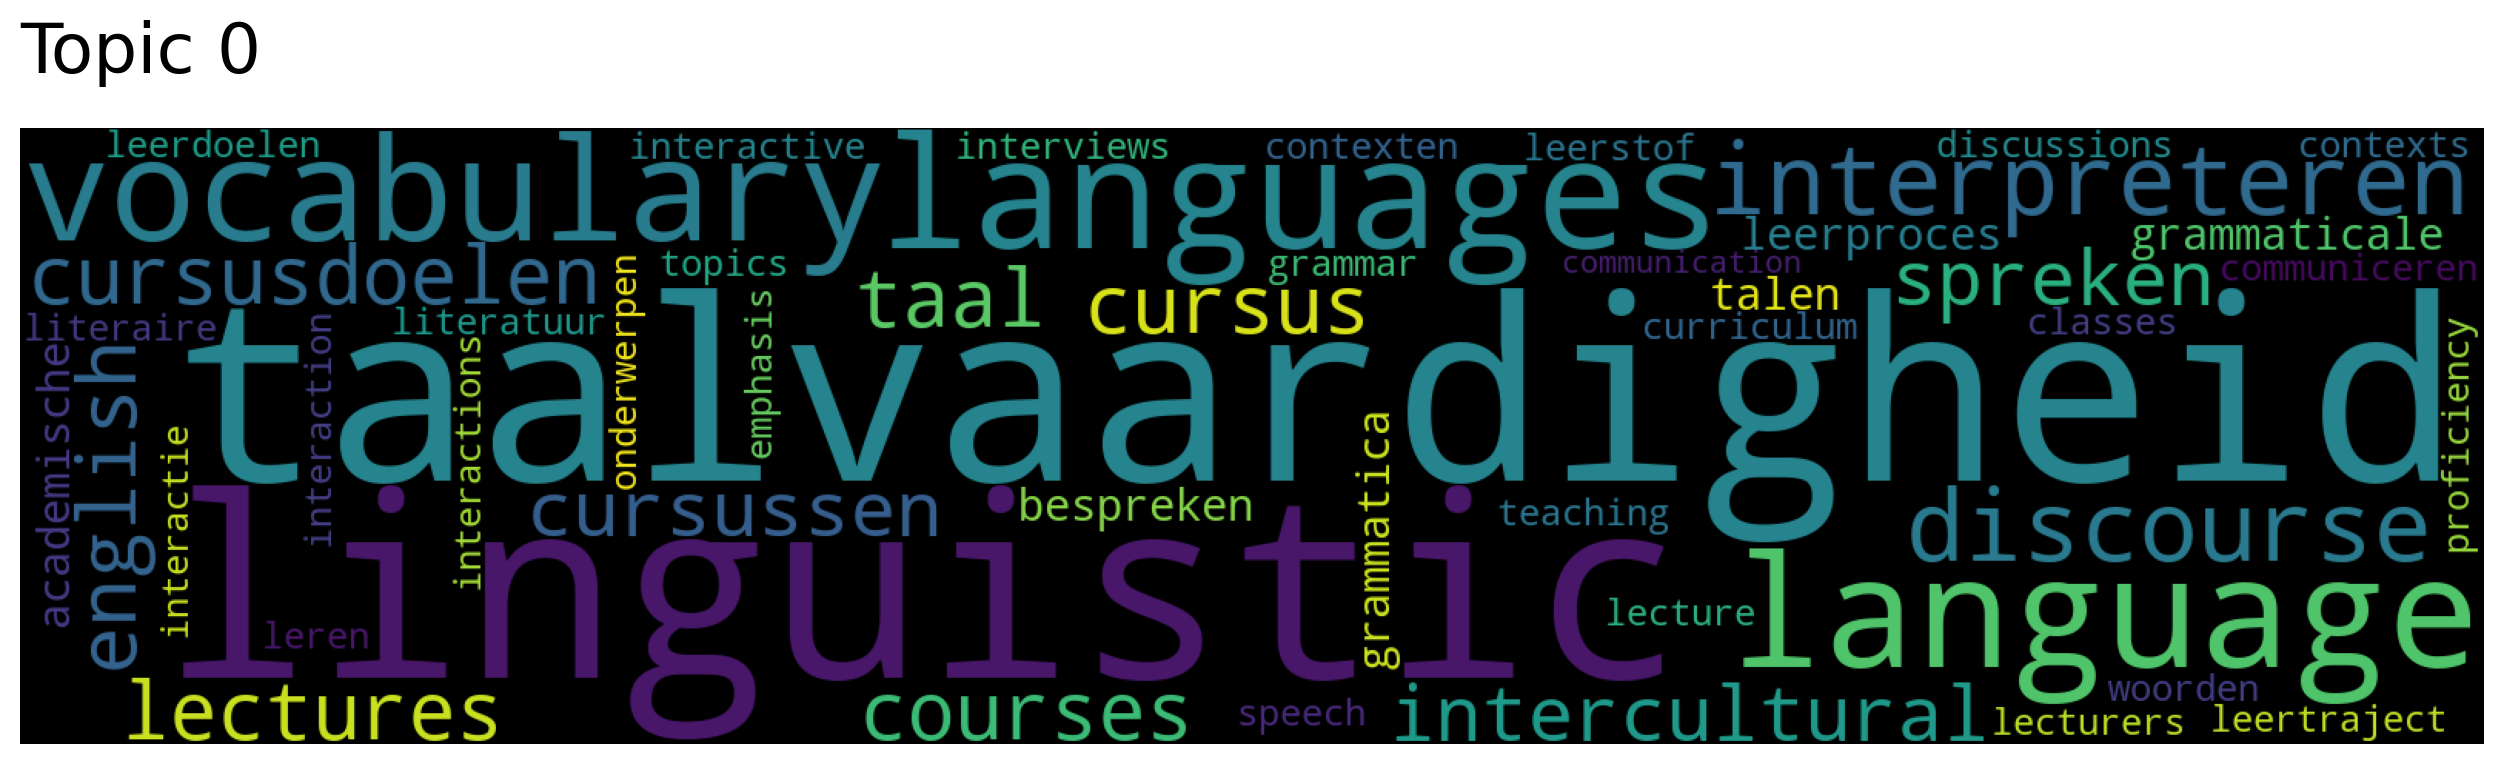

In [67]:
model.generate_topic_wordcloud(0)

In [72]:
topic_words, word_scores, topic_scores, topic_nums = model.search_topics(keywords=['mathematics'], num_topics=39)
print(f"No of topics : {len(topic_nums)} and words are {topic_words[0]}")

No of topics : 39 and words are ['mathematics' 'algebra' 'calculus' 'algorithms' 'computational'
 'mathematical' 'wiskunde' 'programming' 'academische' 'theoretische'
 'theorievorming' 'equations' 'geometry' 'theoretical' 'functions'
 'classes' 'cursus' 'computing' 'courses' 'methodologies' 'academisch'
 'cursussen' 'methodology' 'curriculum' 'functies' 'physics' 'frameworks'
 'methodological' 'complexity' 'function' 'tutorials' 'cursusdoelen'
 'modules' 'integrate' 'functioneren' 'quantum' 'assignments'
 'integration' 'functional' 'concepts' 'theologie' 'linguistic'
 'theoretisch' 'academic' 'basiskennis' 'semester' 'lectures' 'factoren'
 'leerproces' 'program']
